In [1]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import confusion_matrix, classification_report

In [6]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

x_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

x_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

x_train = x_train/255.0
x_test = x_test/255.0

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

Training data:  (27455, 784)
Testing data:  (7172, 784)
Training data:  (27455, 784)
Testing data:  (7172, 784)


In [7]:
x_train = x_train[y_train != 24]

y_test = (y_test == 24).astype(int)

print("Training data: ", x_train.shape)
print("Testing data: ", x_test.shape)

print("Normal samples: ", np.sum(y_test == 0))
print("Anomalous samples: ", np.sum(y_test == 1))

Training data:  (26337, 784)
Testing data:  (7172, 784)
Normal samples:  6840
Anomalous samples:  332


In [9]:
model = Sequential()

model.add(Dense(128, activation='relu', input_shape=(784,)))
model.add(Dense(64, activation='relu'))
model.add(Dense(32, activation='relu'))

model.add(Dense(64, activation='relu'))
model.add(Dense(128, activation='relu'))
model.add(Dense(784, activation='sigmoid'))

model.compile(
    optimizer = tf.keras.optimizers.Adam(),
    loss = 'mse',
    metrics = ['mae']
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_7 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 64)                  │           2,112 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_11 (Dense)                     │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
history = model.fit(
    x_train, x_train,
    epochs = 10,
    batch_size = 256,
    validation_split = 0.2
)

Epoch 1/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.0310 - mae: 0.1369 - val_loss: 0.0255 - val_mae: 0.1217
Epoch 2/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0208 - mae: 0.1085 - val_loss: 0.0187 - val_mae: 0.1004
Epoch 3/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0169 - mae: 0.0958 - val_loss: 0.0161 - val_mae: 0.0925
Epoch 4/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0149 - mae: 0.0886 - val_loss: 0.0150 - val_mae: 0.0909
Epoch 5/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0134 - mae: 0.0831 - val_loss: 0.0128 - val_mae: 0.0800
Epoch 6/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - loss: 0.0126 - mae: 0.0798 - val_loss: 0.0122 - val_mae: 0.0780
Epoch 7/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0118 - mae: 0.0763 - val_loss: 0.0115 - val_mae: 0.0750
Epoch 8/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0111 - mae: 0.0740 - val_loss: 0.0108 - val_mae: 0.0725
Epoch 9/10
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.010

In [12]:
#train
train_predictions = model.predict(x_train)
train_errors = np.mean(np.square(x_train - train_predictions), axis=1)
threshold = np.mean(train_errors) + 3*np.std(train_errors)
print("Threshold: ", threshold)

#test
test_predictions = model.predict(x_test)
errors = np.mean(np.square(x_test - test_predictions), axis=1)

y_pred = (errors > threshold).astype(int)
print("Predicted anomalies: ", y_pred[:20])
print("Total detected anomalies: ", np.sum(y_pred))

824/824 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Threshold:  0.02410197637192768
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Predicted anomalies:  [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Total detected anomalies:  73


In [14]:
print("Confusion matrix: ", confusion_matrix(y_test, y_pred))
print("Classification report: ", classification_report(y_test, y_pred, zero_division=0))

Confusion matrix:  [[6769   71]
 [ 330    2]]
Classification report:                precision    recall  f1-score   support

           0       0.95      0.99      0.97      6840
           1       0.03      0.01      0.01       332

    accuracy                           0.94      7172
   macro avg       0.49      0.50      0.49      7172
weighted avg       0.91      0.94      0.93      7172



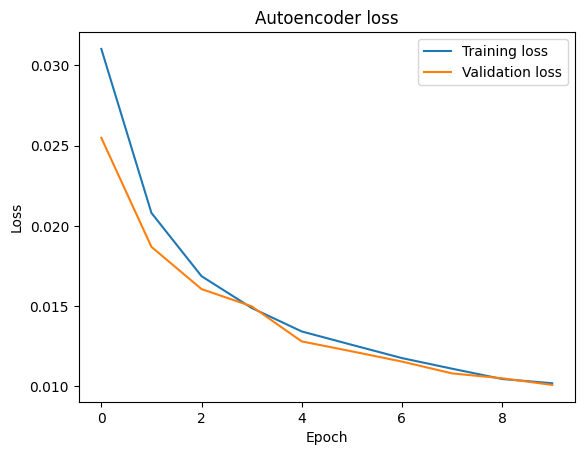

In [13]:
plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title("Autoencoder loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.show()